# Predicting Diabetes Progression

## 1. Problem Statement

The objective of this lab is to predict a patient's disease progression
one year after baseline. Baseline means the starting point when the
patient measurements were collected.

The dataset contains patients who already have diabetes. We are
predicting a numerical progression score, rather than whether someone
has diabetes. The score is not a probability or a percentage.

This is a supervised regression problem. The input features are patient
measurements, and the target is the known progression score.

### Purpose

The proposed model could help physicians identify patients who may
need closer follow-up.

Underestimating progression could mean overlooking a patient who needs
attention. Overestimating progression could lead to unnecessary
follow-up. Therefore, we need to examine prediction errors as well as
overall performance.

### Models and Evaluation

In Part 2, we will use BMI to compare polynomial regression models
with degrees from 0 to 5.

In Part 3, we will compare models using multiple features, including
polynomial regression, decision tree regression, and kNN regression.

We will evaluate regression models using:

- R-squared (R²): Higher values indicate better performance relative
  to predicting the mean. R² can be negative.
- Mean Absolute Error (MAE): Measures average absolute error in
  progression-score units. Lower values are better.
- Mean Absolute Percentage Error (MAPE): Measures average relative
  error. Lower values are better. It can give more weight to errors
  for smaller target values.

The data will be divided into approximately 75% training, 10% validation,
and 15% testing. We will select models using validation results and
reserve the test set for final evaluation.

### Connections to the Workshops

The Performance Metrics workshop showed why one metric alone may hide
important errors. We will use several metrics and investigate where
our predictions fail.

The kNN workshop showed that feature scaling and the number of
neighbors affect predictions. We will consider both when developing
our kNN regression models.

The Logistic Regression workshop introduced probabilities and decision
thresholds. We apply these ideas in a separate classification task:
predicting whether progression is below or at/above the training-set
median of 142.0.

This is a statistical category, not a validated clinical risk level.
Classification results are evaluated separately from regression results.
The category definition remains subject to instructor confirmation.

### Limitations

This is a small educational dataset. Performance on this dataset alone
does not establish that a model is suitable for clinical screening.


## 2. Import the Data Loader Class

We use an object-oriented approach to organize the code.

The DiabetesDataLoader class is stored in src/data_loader.py.
It handles loading the dataset and providing basic information.

The notebook calls the class methods and explains their results.
This keeps the report readable and the data-loading code reusable.

In [1]:
from src.data_loader import DiabetesDataLoader

## 3. Create the Data Loader Object

A class describes what an object can store and do. Here, we create
an object named loader from the DiabetesDataLoader class.

We select scaled=False to load the original feature values. This
makes measurements such as BMI easier to interpret.

Scikit-Learn scales the features by default. A scaled BMI value
should not be interpreted as an ordinary BMI measurement.

Later, we will fit scaling on training data where needed, especially
for kNN.

In [2]:
loader = DiabetesDataLoader(scaled=False)

## 4. Load the Dataset

We call load_data() to load the diabetes dataset.

This method stores the inputs and target inside the loader object.
It also returns a combined pandas DataFrame, which we save as df
for exploration.

The combined table includes a target column named progression.
A separate CSV download is not required.

In [3]:
df = loader.load_data()

print("Dataset loaded successfully.")

Dataset loaded successfully.


## 5. Read the Official Dataset Description

Before exploring the data, we read the description supplied by
Scikit-Learn. It explains the dataset's background, features, and target.

Any reference to centered and scaled features describes the loader's
default behavior. We selected scaled=False to use the original values.

In [4]:
print(loader.get_description())

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

## 6. Understand the Columns

Each row represents one patient.

| Column | Description |
|---|---|
| age | Age in years |
| sex | Coded sex variable |
| bmi | Body mass index |
| bp | Average blood pressure |
| s1 | Total serum cholesterol |
| s2 | Low-density lipoproteins (LDL) |
| s3 | High-density lipoproteins (HDL) |
| s4 | Total cholesterol / HDL ratio |
| s5 | Possibly the log of serum triglycerides |
| s6 | Blood sugar level |
| progression | Disease progression one year after baseline |

The documentation notes some uncertainty about the original meanings
of certain serum features, particularly s5.

We display the first five rows to check the column names and values.
The leftmost index is a row label, not an extra input feature.

In [5]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


## 7. Check the Dataset Size

We use get_summary() to check the number of patients, input features,
and the target range.

There should be 442 patients and 10 input features. The combined table
should have 11 columns because it also contains progression.

In [6]:
summary = loader.get_summary()

print("Number of patients:", summary["number_of_patients"])
print("Number of input features:", summary["number_of_features"])
print("Combined table shape:", summary["combined_shape"])
print("Target column:", summary["target_name"])

print(
    "Target range:",
    summary["target_minimum"],
    "to",
    summary["target_maximum"]
)

Number of patients: 442
Number of input features: 10
Combined table shape: (442, 11)
Target column: progression
Target range: 25.0 to 346.0


## 8. Separate the Inputs and Target

X contains the baseline measurements that the models will use.

y contains the progression score that the models will learn to predict.

The target must remain outside X. Including the answer among the
inputs would cause target leakage and produce misleading results.
This step separates the columns; it does not split the patients into
training, validation, and test sets yet.

In [7]:
X, y = loader.get_features_and_target()

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

print("\nFirst five target values:")
print(y.head())

Input shape: (442, 10)
Target shape: (442,)

Input columns:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First five target values:
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: progression, dtype: float64


## 9. Initial Observations

The dataset contains 442 patients and 10 baseline input features.
The target is a numerical progression score measured one year later.

We loaded the original feature values so measurements such as BMI
are easier to interpret.

The data-loading code is organized inside the DiabetesDataLoader class.
The notebook uses its methods to load and inspect the data.

We have not yet determined whether cleaning is needed or which
features are most useful. The next step is exploratory data analysis.

## 10. Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the dataset before
building models.

We will examine:

- Column types and missing values.
- Summary statistics.
- Duplicate records.
- Distributions using histograms.
- Relationships using scatter plots.
- Correlations between variables.

We use the DiabetesDataExplorer class to keep the exploration code
organized and reusable.

These initial plots describe the dataset. We will keep the test set
out of later feature-selection, preprocessing, and model-tuning decisions.

In [8]:
from src.data_explorer import DiabetesDataExplorer

explorer = DiabetesDataExplorer(
    data=df,
    target_column="progression"
)

## 11. Check Column Types and Missing Values

We check the type of data stored in each column and whether any values
are missing.

The unique-value count shows how many different values a column contains.
For example, sex is a coded categorical variable even though it is
stored numerically.

A numeric data type does not automatically mean that a variable is
a continuous measurement.

In [9]:
overview = explorer.get_data_overview()

overview

,data_type,non_missing_values,missing_values,unique_values
age,float64,442,0,58
sex,float64,442,0,2
bmi,float64,442,0,163
bp,float64,442,0,100
s1,float64,442,0,141
s2,float64,442,0,302
s3,float64,442,0,63
s4,float64,442,0,66
s5,float64,442,0,184
s6,float64,442,0,56


## 12. Summary Statistics

We calculate summary statistics for the numeric columns.

- count: Number of non-missing values.
- mean: Average value.
- std: Standard deviation, describing how spread out the values are.
- min and max: Smallest and largest values.
- 25%, 50%, and 75%: Quartiles; 50% is the median.

Comparing the mean and median can help us notice possible asymmetry.
The minimum and maximum help us identify values worth investigating.

The mean of a coded categorical variable, such as sex, should not be
interpreted like the mean of BMI or age.

In [10]:
statistics = explorer.get_statistics()

statistics.round(2)

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00


## 13. Check for Duplicate Records

We count rows that have identical values across all input features
and the target.

Identical rows are worth checking, but they do not automatically prove
that a record is an error. Different patients can sometimes have the
same recorded measurements.

We will use the result to explain our cleaning decision.

In [11]:
duplicate_count = explorer.count_duplicates()

print("Number of fully duplicated rows:", duplicate_count)

Number of fully duplicated rows: 0


## 14. Examine the Distributions

Histograms show how frequently values occur within different ranges.

We use them to examine the typical range, spread, and shape of each
variable. We also look for skewness and unusual values.

An unusual value is not automatically incorrect. It may represent a
patient with a less common but valid measurement.

For the coded sex variable, the separated bars represent categories;
the spaces between those codes do not represent intermediate categories.

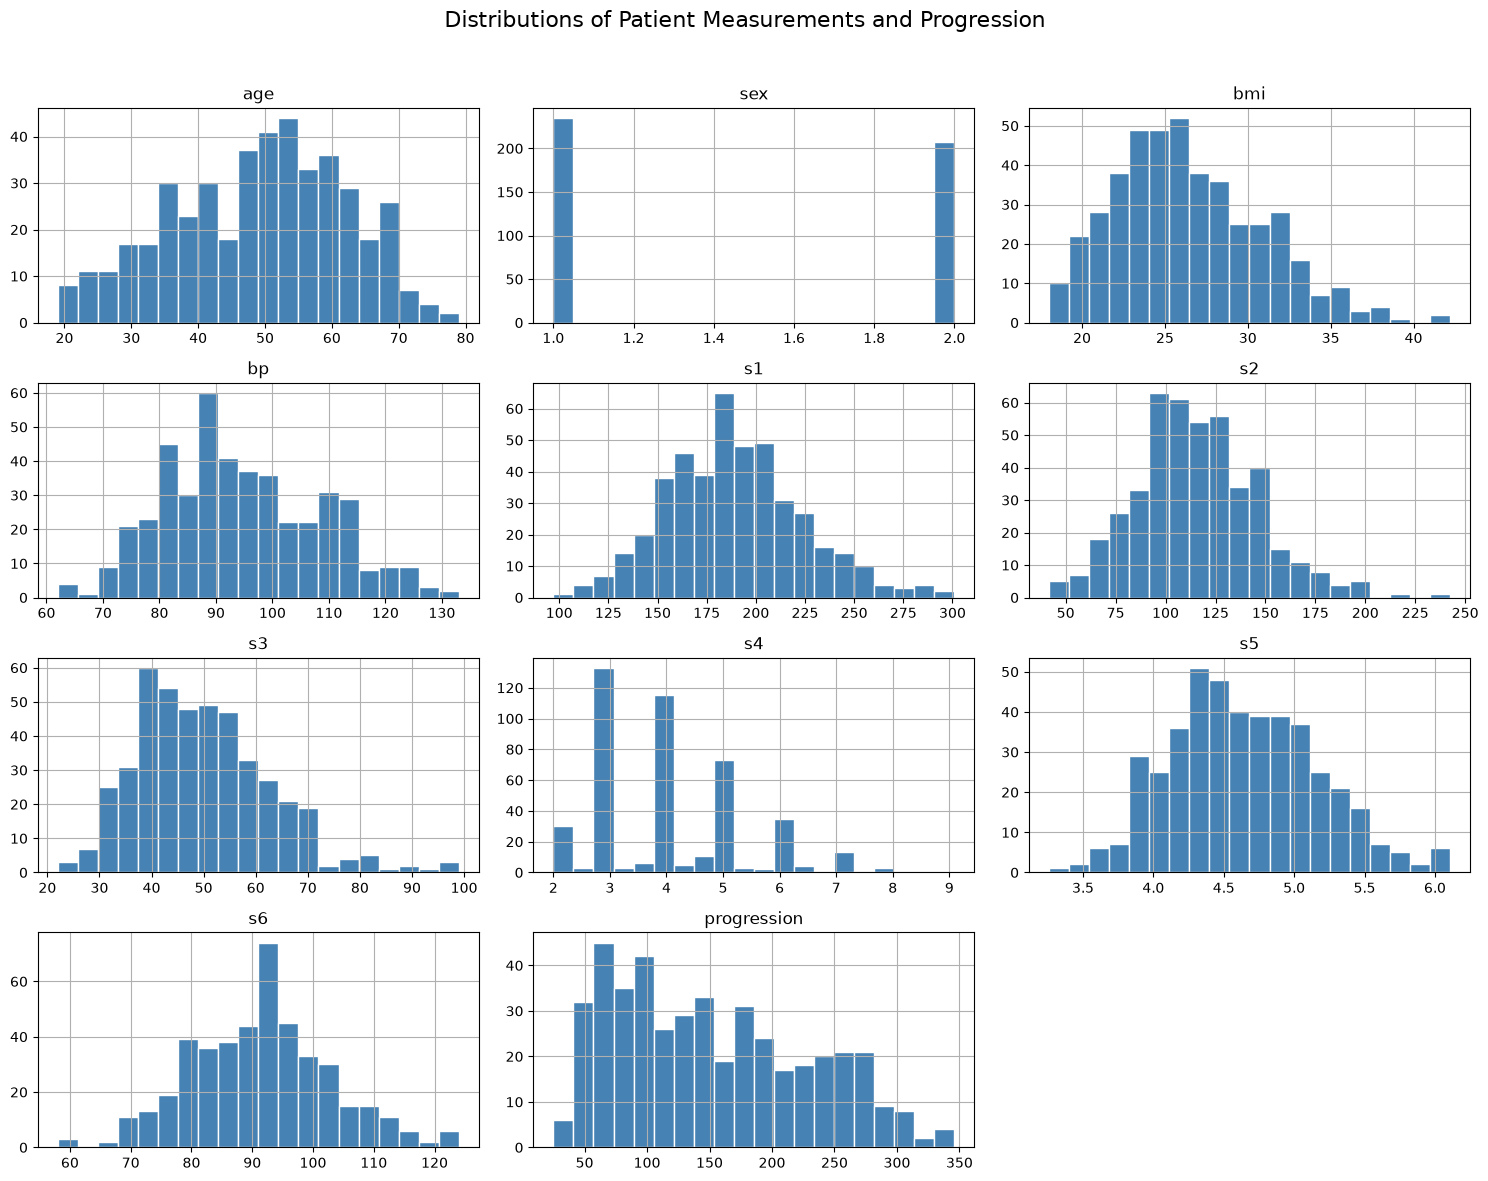

In [12]:
explorer.plot_histograms()

## 15. Explore Features against Disease Progression

Each scatter plot compares one baseline feature with the progression
score. Each point represents one patient.

An upward pattern suggests that larger feature values tend to appear
with larger progression scores. A downward pattern suggests the opposite.

A wide vertical spread means patients with similar values of that
feature can have very different progression scores.

We pay particular attention to BMI because Part 2 requires BMI as the
only input feature. These plots show associations, not proof of cause
and effect.

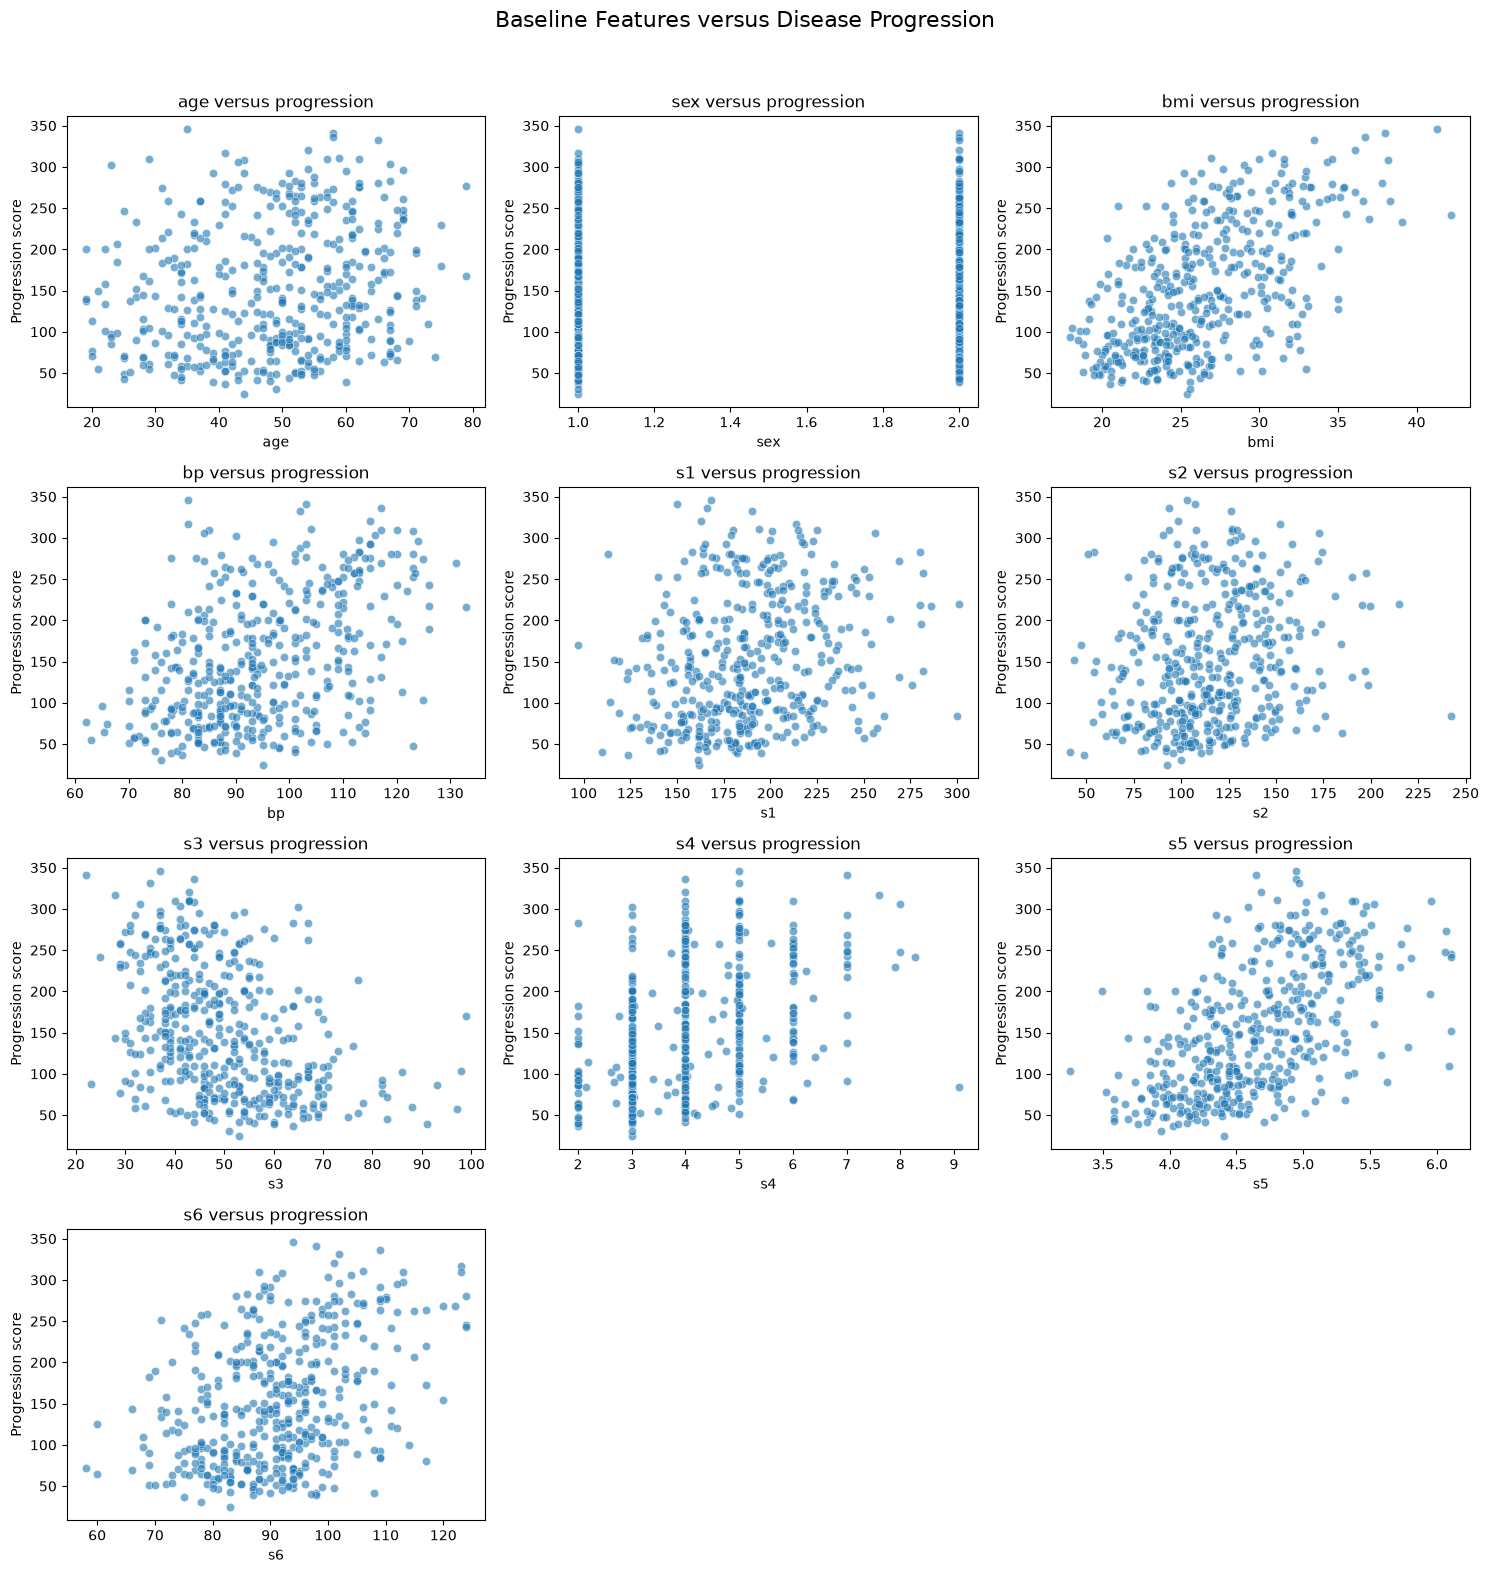

In [13]:
explorer.plot_scatter_plots()

## 16. Correlation Matrix

The heatmap shows Pearson correlation, which measures linear association.

- Values near +1 indicate a strong positive linear association.
- Values near -1 indicate a strong negative linear association.
- Values near 0 indicate a weak linear association.

A correlation near zero does not rule out a nonlinear relationship.

We examine correlations with progression and correlations between input
features. Strong correlations between inputs may indicate overlapping
information, but they are not enough by themselves to justify removing
a feature.

Correlations involving coded variables should be interpreted carefully.

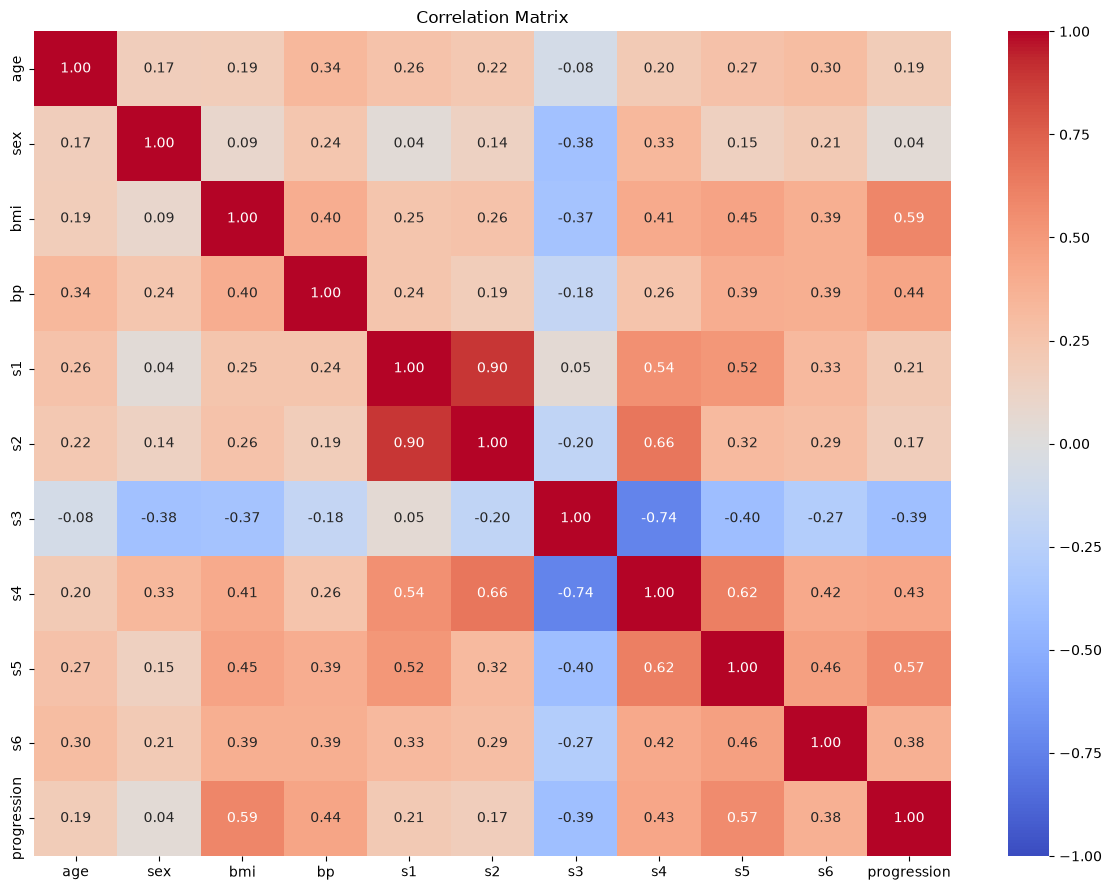

In [14]:
explorer.plot_correlation_matrix()

## 17. Compare Correlations with Progression

The following table orders features by the absolute size of their
correlation with progression.

The signs remain visible so we can distinguish positive and negative
relationships.

This table describes linear associations. It does not prove that the
highest-correlated feature will produce the best predictive model.

In [15]:
target_correlations = explorer.get_target_correlations()

target_correlations.round(3)

,correlation_with_progression
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s3,-0.395
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043


## 18. EDA Findings

The dataset contains 442 patients, with no missing values or fully
duplicated rows. BMI ranges from 18.0 to 42.2, while progression
scores range from 25 to 346.

BMI and s5 have the strongest positive correlations with progression,
approximately 0.586 and 0.566. However, patients with similar BMI
values have different progression scores, suggesting BMI alone
cannot explain all the variation.

The s3 feature has a negative correlation with progression (-0.395).
The strong correlation between s1 and s2 (0.90) suggests overlapping
information. Correlation does not establish causation.

Some distributions have longer upper tails. We will retain all
features initially and use training and validation data to guide
any later feature-selection decisions.

## 19. Data Cleaning Decision

No imputation or duplicate removal is needed because the dataset has
no missing values or fully duplicated rows. All columns are numeric,
although sex represents a coded category.

We will retain unusual values because there is no evidence that they
are recording errors. All 442 patients will be kept.

For models that need scaling, such as kNN, the scaler will be fitted
only on the training data.

## 20. Split the Dataset

We divide the patients into three separate sets:

- Training (75%): Used to fit the models.
- Validation (10%): Used to compare models and choose their settings.
- Test (15%): Reserved for the final evaluation.

First, we separate 75% for training. We then divide the remaining
25% into validation and test sets.

We use random_state=42 to reproduce the same split each time.
The percentages are approximate because patients cannot be divided
into fractions.

The same patient splits will be used for all models.

In [16]:
from src.data_splitter import DiabetesDataSplitter

splitter = DiabetesDataSplitter(random_state=42)

X_train, X_val, X_test, y_train, y_val, y_test = splitter.split(X, y)

## 21. Check the Split Sizes

We check how many patients are in each set and the actual percentages.
Together, the three sets should contain all 442 patients.

In [17]:
import pandas as pd

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Patients": [len(X_train), len(X_val), len(X_test)]
})

split_summary["Percentage"] = (
    split_summary["Patients"] / len(X) * 100
).round(2)

split_summary

,Dataset,Patients,Percentage
0,Training,331,74.89
1,Validation,44,9.95
2,Test,67,15.16


## 22. Verify the Split

We check that each patient belongs to only one set and that each
input row remains matched with its correct target value.

In [18]:
# Check that all patients are included
assert len(X_train) + len(X_val) + len(X_test) == len(X)

# Check that no patient appears in more than one set
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty

# Check that inputs and targets remain aligned
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

print("Split verified: all patients are included with no overlap.")

Split verified: all patients are included with no overlap.


## 23. Split Summary

The split contains 331 training patients, 44 validation patients,
and 67 test patients, closely matching the required 75%/10%/15% ratio.

Any learned preprocessing, such as scaling, will be fitted only on
training data and then applied to validation and test data.

Next, we will train six polynomial regression models using BMI only.

# Part 2: Univariate Polynomial Regression

## 24. Models Using BMI Only

We will train six models using BMI as the only input and progression
as the target.

- Degree 0: Predicts the training progression mean for every patient.
- Degree 1: Fits a straight line.
- Degrees 2–5: Allow increasingly flexible curves.

The degree-0 model is our baseline. More complex models should provide
useful improvement over this simple prediction.

A higher degree may fit training data better but can also overfit.
We will compare training and validation results before choosing a model.

In [19]:
from src.polynomial_regression import UnivariatePolynomialRegression

polynomial_experiment = UnivariatePolynomialRegression(
    feature="bmi",
    max_degree=5
)

## 25. Train and Compare the Models

Each model learns from the training set only.

For degrees 1–5, a pipeline scales BMI, creates polynomial terms,
and fits linear regression. Scaling improves numerical stability
without changing the polynomial degree.

We evaluate each model on both training and validation data using
R², MAE, and MAPE. MAPE is multiplied by 100 to display percentages.

The test set is not used during this comparison.

In [20]:
comparison_table = polynomial_experiment.train_and_compare(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val
)

comparison_table.round(3)

,Degree,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,0,0.000,-0.107,66.202,66.057,62.827,71.264
1,1,0.350,0.331,52.288,47.208,48.363,47.060
2,2,0.351,0.332,52.207,47.214,48.299,47.240
3,3,0.351,0.332,52.199,47.185,48.281,47.223
4,4,0.353,0.341,52.093,46.090,48.053,46.050
5,5,0.354,0.350,52.059,45.462,48.004,45.175


## 26. Compare Validation Performance

We use validation MAE as our main selection metric because it reports
the average absolute error in progression-score units.

We also examine validation R² and MAPE, along with the difference
between training and validation performance.

A model with much better training results than validation results
may be overfitting. If performance is very similar, a simpler model
may be preferable.

In [21]:
ranked_models = comparison_table.sort_values(
    by=["Validation MAE", "Degree"]
)

ranked_models.round(3)

,Degree,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
5,5,0.354,0.350,52.059,45.462,48.004,45.175
4,4,0.353,0.341,52.093,46.090,48.053,46.050
3,3,0.351,0.332,52.199,47.185,48.281,47.223
1,1,0.350,0.331,52.288,47.208,48.363,47.060
2,2,0.351,0.332,52.207,47.214,48.299,47.240
0,0,0.000,-0.107,66.202,66.057,62.827,71.264


## 27. Select the Best Model

We select the degree-5 polynomial because it has the lowest validation
MAE (45.462). It also has the highest validation R² (0.350) and the
lowest validation MAPE (45.175%).

Its improvement over degree 4 is small, so this result does not prove
that degree 5 will always perform best on new samples.

Training and validation R² are similar, providing no clear evidence
of substantial overfitting on this split. However, the validation set
contains only 44 patients, so the comparison has uncertainty.

We will now evaluate the selected model on the untouched test set.

In [22]:
best_degree = int(ranked_models.iloc[0]["Degree"])

print("Selected polynomial degree:", best_degree)

Selected polynomial degree: 5


## 28. Evaluate the Selected Model on Test Data

The test set contains 67 patients who were not used to train or select
the model.

We use the already-trained degree-5 model to predict their progression
scores, then calculate R², MAE, and MAPE.

These results estimate performance on unseen patients from the same
data source. We will not use the test results to change the selected
degree.

In [23]:
from src.model_evaluator import RegressionEvaluator

# Predict using the existing trained model
test_predictions = polynomial_experiment.predict(
    degree=best_degree,
    X=X_test
)

# Evaluate the predictions
evaluator = RegressionEvaluator()

test_results = evaluator.evaluate(
    y_true=y_test,
    y_pred=test_predictions,
    model_name=f"BMI polynomial degree {best_degree}"
)

test_results.round(3)

,Model,R2,MAE,MAPE (%)
0,BMI polynomial degree 5,0.267,51.75,43.027


## 29. Test Results

The selected degree-5 model achieved a test R² of 0.267, MAE of
51.75, and MAPE of 43.03%.

Its predictions differ from the actual progression scores by
51.75 points on average. The test R² is lower than the validation
R² (0.350), and test MAE is higher than validation MAE (45.462),
indicating weaker performance on the test patients.

Although test MAPE is lower, it measures relative error and can
behave differently from MAE across samples.

These results suggest that BMI alone provides limited predictive
information. We will retain the selected model and examine its
fitted curve and prediction errors next.

## 30. Plot the Selected Model

We plot the training, validation, and test patients in separate panels.
Each point shows a patient's BMI and actual progression score.

The black curve represents predictions from the selected degree-5
model. The same curve appears in every panel because the model was
fitted only on training data.

The vertical distance between a point and the curve represents its
prediction error. Points above the curve are underpredicted, while
points below it are overpredicted.

The axes use the same scales so the panels can be compared directly.

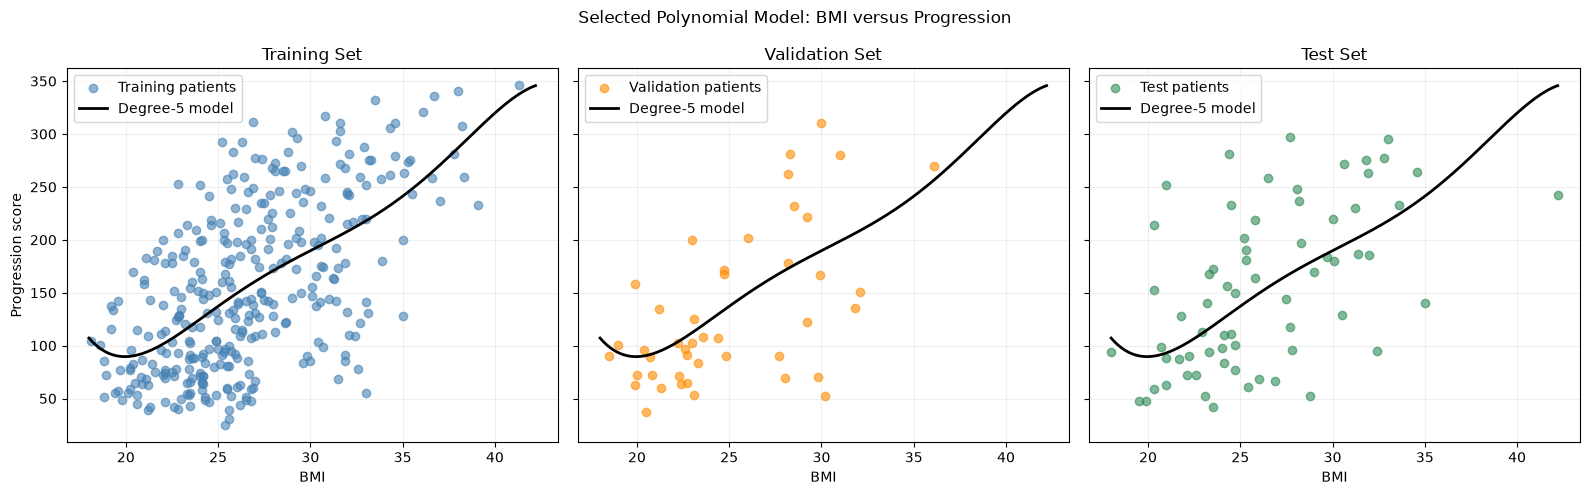

In [24]:
from src.model_visualizer import PolynomialModelVisualizer

visualizer = PolynomialModelVisualizer(
    experiment=polynomial_experiment,
    degree=best_degree
)

visualizer.plot_fit(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test
)

## 31. Interpretation of the Fitted Curve

The curve generally predicts higher progression scores as BMI increases,
with a small dip at the lowest BMI values.

There is considerable scatter around the curve. Patients with similar
BMI values have different progression scores, showing the limitations
of using BMI alone.

Several patients with high progression scores lie well above the curve,
meaning the model underpredicts their progression. Some patients with
low scores lie below the curve and are overpredicted.

There are few observations at the highest BMI values, so the curve
in that region is supported by limited data. Predictions outside the
training BMI range should be treated cautiously.

## 32. Equation of the Selected Model

Our pipeline standardizes BMI before creating polynomial terms.
Therefore, the equation uses z, which represents standardized BMI.

The code below displays the fitted equation with coefficients rounded
to two decimal places. It also shows how to calculate z from raw BMI
using the training mean and scale.

Predictions will use the original fitted model at full precision.

In [25]:
from src.model_inspector import PolynomialModelInspector

inspector = PolynomialModelInspector(
    experiment=polynomial_experiment
)

print(inspector.get_equation(best_degree))

Predicted progression = 156.10 + 49.11*z - 8.70*z^2 - 1.04*z^3 + 3.55*z^4 - 0.70*z^5

z = (BMI - 26.591541) / 4.373650


## 33. Predict Progression for an Example BMI

We choose a BMI of 30.0, which is within the observed training range.

We pass the raw BMI into predict(). The pipeline automatically applies
the training scaler and polynomial transformation.

The result is an estimated progression score, not a probability or
a diagnosis.

In [26]:
example_bmi = 30.0

example_patient = pd.DataFrame({
    "bmi": [example_bmi]
})

example_prediction = polynomial_experiment.predict(
    degree=best_degree,
    X=example_patient
)[0]

print(f"Example BMI: {example_bmi:.1f}")
print(
    f"Predicted progression score: {example_prediction:.2f}"
)

Example BMI: 30.0
Predicted progression score: 189.70


## 34. Number of Fitted Parameters

A univariate polynomial of degree d has d coefficients plus one
intercept, giving d + 1 regression parameters.

The degree-0 baseline fits one constant: the training target mean.
The degree-5 model fits five coefficients and one intercept.

We use get_feature_names_out() to identify the polynomial terms.
The intercept is counted separately because include_bias=False
excludes a constant column.

These counts describe the regression parameters. The scaler also
stores the training BMI mean and scale as preprocessing statistics.

In [27]:
parameter_table = inspector.get_parameter_counts()

parameter_table

,Degree,Terms,Fitted regression parameters
0,0,constant,1
1,1,z,2
2,2,"z, z^2",3
3,3,"z, z^2, z^3",4
4,4,"z, z^2, z^3, z^4",5
5,5,"z, z^2, z^3, z^4, z^5",6


## 35. Examine the Largest Prediction Errors

We inspect the ten test patients with the largest absolute errors.

Residual = actual score − predicted score.

A positive residual means the model underpredicted progression.
A negative residual means it overpredicted progression.

This helps us understand failures that average metrics may hide.

In [28]:
from src.error_analyzer import RegressionErrorAnalyzer

error_analyzer = RegressionErrorAnalyzer(
    X=X_test,
    y_true=y_test,
    y_pred=test_predictions
)

error_analyzer.get_largest_errors().round(2)

,bmi,actual,predicted,residual,absolute_error
78,21.0,252.0,93.12,158.88,158.88
117,24.4,281.0,129.68,151.32,151.32
113,27.7,297.0,167.98,129.02,129.02
380,28.8,52.0,178.75,-126.75,126.75
218,20.3,214.0,90.02,123.98,123.98
104,32.4,95.0,211.70,-116.70,116.70
367,42.2,242.0,345.71,-103.71,103.71
395,26.5,258.0,155.07,102.93,102.93
285,24.5,233.0,130.94,102.06,102.06
407,35.0,140.0,241.16,-101.16,101.16


## 36. Compare Errors across Progression Levels

We divide actual test outcomes into lower, middle, and higher
progression groups using the training target's 25th and 75th percentiles.

These groups are for describing errors, not clinical risk categories.

We compare MAE and mean residual within each group. A positive mean
residual indicates average underprediction, while a negative value
indicates average overprediction.

Group sizes are reported because results based on few patients
are less reliable.

In [29]:
error_analyzer.get_group_summary(y_train).round(2)

,patients,MAE,mean_residual
progression_group,,,
Lower,14,59.22,-59.22
Middle,35,35.45,-1.65
Higher,18,77.62,66.10


## 37. Residual Plot

The dashed line represents a prediction with zero error.

Points above the line are underpredictions, and points below it
are overpredictions. Large distances from the line indicate large errors.

We examine whether errors show a pattern or change in spread across
predicted scores. This analysis describes the selected model;
we will not use it to tune the model on test data.

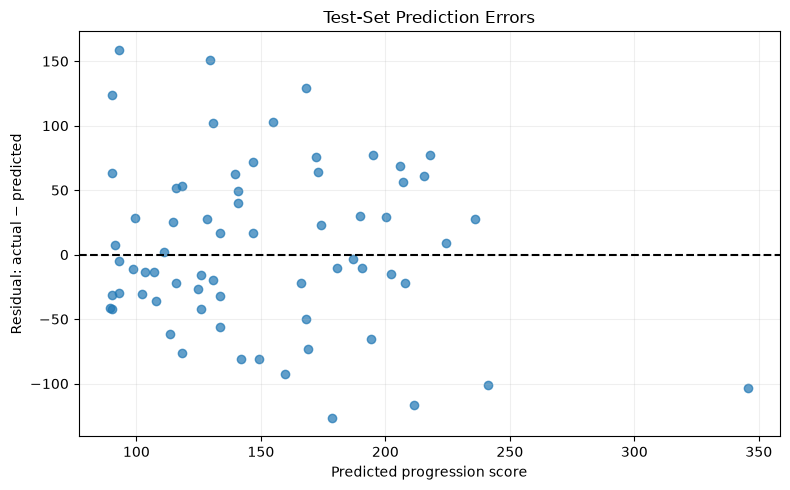

In [30]:
error_analyzer.plot_residuals()

## 38. Part 2 Conclusion and Limitations

### Performance

The degree-5 polynomial performed best on validation data.
On the test set, it achieved R² = 0.267, MAE = 51.75, and
MAPE = 43.03%. Its improvement over simpler polynomials was modest,
suggesting that increasing complexity provides limited benefit
when BMI is the only input.

### Where the Model Fails

The model performed best for the middle progression group, with
MAE = 35.45. Errors were larger for the lower group (59.22) and
higher group (77.62).

The lower group was overpredicted on average, with a mean residual
of -59.22. The higher group was underpredicted on average, with
a mean residual of +66.10.

The largest error involved a patient with BMI 21.0: the actual
progression score was 252, but the prediction was 93.12. Another
patient with BMI 28.8 had an actual score of 52 but was predicted
178.75. These examples show that similar BMI measurements cannot
reliably determine an individual's progression.

### Workshop Connections

The Performance Metrics workshop demonstrated why overall scores
should be supported by error analysis. Here, average performance
hides larger errors for patients with higher progression scores.

The kNN workshop highlighted the limitations of small evaluation
samples. Our validation and test sets contain only 44 and 67
patients, so results may vary with a different split.

The Logistic Regression workshop discussed probabilities and decision
thresholds. Our regression predictions are scores, not probabilities.
Using them to flag patients would require a justified threshold and
separate evaluation of errors such as missed high-progression cases.

### Limitations

BMI alone omits other potentially useful patient measurements.
The dataset is small, and few patients have very high BMI values.
The polynomial may behave unpredictably outside the training range.

These results do not establish clinical screening suitability.
Part 3 will investigate whether multiple features improve predictions.

# Part 3: Models Using Multiple Features

## 39. Features and Models

We will use all 10 baseline features. Although some features have weak
individual correlations with progression, they may provide useful
information when combined with other measurements.

We will compare:

- Polynomial regression with degrees 2 and 3.
- Decision trees with maximum depths of 3 and 5.
- kNN regression with 5 and 15 neighbors.

The polynomial models include powers and interactions between features.
For example, an interaction can represent BMI multiplied by blood
pressure.

We will reuse the existing training, validation, and test splits.

In [31]:
from src.multivariate_models import MultivariateModelComparison

multivariate_experiment = MultivariateModelComparison(
    random_state=42
)

print("Input features:", X_train.columns.tolist())
print("Number of input features:", X_train.shape[1])

Input features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Number of input features: 10


## 40. Train and Compare the Models

All models are fitted using training data only.

Polynomial regression and kNN use scaling fitted within their
pipelines. Decision trees use the original feature values because
standard scaling is not required for their split decisions.

We compare training and validation R², MAE, and MAPE. As in Part 2,
validation MAE is our main selection metric.

Multivariate polynomial models can create many terms, including
correlated or redundant terms. Degree 3 may therefore be unstable
or overfit this small dataset. We will examine its results rather
than assume that greater complexity improves predictions.

The test set is not used in this comparison.

In [32]:
multivariate_results = multivariate_experiment.train_and_compare(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val
)

multivariate_results.round(3)

,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,Polynomial degree 2,0.605,0.426,39.216,41.802,34.606,42.277
1,Polynomial degree 3,0.909,-24.612,15.637,213.935,14.338,207.507
2,Decision tree depth 3,0.510,0.198,44.260,48.126,38.867,47.673
3,Decision tree depth 5,0.687,0.094,33.527,49.645,29.974,48.162
4,kNN k=5,0.568,0.326,40.839,44.245,35.060,41.800
5,kNN k=15,0.491,0.366,44.869,44.718,39.179,45.459


## 41. Rank the Models

We rank the models by validation MAE, with lower values preferred.

We also examine R², MAPE, and the difference between training and
validation results. Strong training performance followed by poor
validation performance suggests overfitting.

We will finalize the selection before evaluating the selected
models on the test set.

In [33]:
ranked_multivariate_models = multivariate_results.sort_values(
    by=["Validation MAE", "Model"]
)

ranked_multivariate_models.round(3)

,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,Polynomial degree 2,0.605,0.426,39.216,41.802,34.606,42.277
4,kNN k=5,0.568,0.326,40.839,44.245,35.060,41.800
5,kNN k=15,0.491,0.366,44.869,44.718,39.179,45.459
2,Decision tree depth 3,0.510,0.198,44.260,48.126,38.867,47.673
3,Decision tree depth 5,0.687,0.094,33.527,49.645,29.974,48.162
1,Polynomial degree 3,0.909,-24.612,15.637,213.935,14.338,207.507


## 42. Model Comparison and Selection

The degree-2 polynomial achieved the lowest validation MAE (41.802)
and highest validation R² (0.426). We select it as the best overall
regression model among these six configurations.

The degree-3 polynomial shows severe overfitting. Its training R²
is 0.909, but validation R² falls to -24.612. Its many polynomial
terms and correlated inputs may also contribute to instability.
A negative R² is valid and indicates poor predictive performance.

The depth-5 decision tree fits training data better than depth 3,
but performs worse on validation data. We therefore select depth 3.

For kNN, k=5 has lower validation MAE and MAPE than k=15, although
k=15 has higher R². We select k=5 because validation MAE is our
primary criterion.

The degree-2 multivariate model improves validation MAE from 45.462
for the selected BMI-only model to 41.802. This suggests that the
additional features provide useful predictive information on this split.

These choices are based on validation results. We will keep them
fixed during test evaluation.

## 43. Evaluate the Selected Models on Test Data

Using validation MAE, we selected:

- Polynomial regression: degree 2.
- Decision tree: maximum depth 3.
- kNN regression: 5 neighbors.

The degree-2 polynomial is our overall selection based on validation
performance.

We now evaluate these three trained models on the same 67 test
patients. We keep the fitted models unchanged and do not use test
results to select new settings.

In [34]:
selected_model_names = [
    "Polynomial degree 2",
    "Decision tree depth 3",
    "kNN k=5"
]

# Preserve the overall choice made using validation data
best_multivariate_name = "Polynomial degree 2"

multivariate_test_predictions = {}
evaluation_tables = []

for model_name in selected_model_names:
    predictions = multivariate_experiment.predict(
        model_name=model_name,
        X=X_test
    )

    multivariate_test_predictions[model_name] = predictions

    model_results = evaluator.evaluate(
        y_true=y_test,
        y_pred=predictions,
        model_name=model_name
    )

    evaluation_tables.append(model_results)

multivariate_test_results = pd.concat(
    evaluation_tables,
    ignore_index=True
)

multivariate_test_results.round(3)

,Model,R2,MAE,MAPE (%)
0,Polynomial degree 2,0.399,45.493,37.949
1,Decision tree depth 3,0.438,46.115,40.176
2,kNN k=5,0.471,42.209,34.653


## 44. Compare with the BMI-Only Model

We place the selected multivariate models alongside the degree-5
BMI-only model evaluated in Part 2.

All results use the same test patients, allowing a direct comparison.
This shows whether the selected models using multiple features
improved upon the BMI-only model on this test sample.

Our overall model selection remains based on validation performance.

In [35]:
combined_test_results = pd.concat(
    [
        test_results,
        multivariate_test_results
    ],
    ignore_index=True
)

combined_test_results.round(3)

,Model,R2,MAE,MAPE (%)
0,BMI polynomial degree 5,0.267,51.750,43.027
1,Polynomial degree 2,0.399,45.493,37.949
2,Decision tree depth 3,0.438,46.115,40.176
3,kNN k=5,0.471,42.209,34.653


## 45. Plot Actual versus Predicted Progression

We compare the selected polynomial, decision tree, and kNN models
on training, validation, and test data.

Each point represents one patient. The dashed diagonal represents
a perfect prediction.

- Points near the diagonal have smaller errors.
- Points below the diagonal are underpredictions.
- Points above the diagonal are overpredictions.

The same trained model is used across its three panels. All panels
use the same axis scales to support comparison.

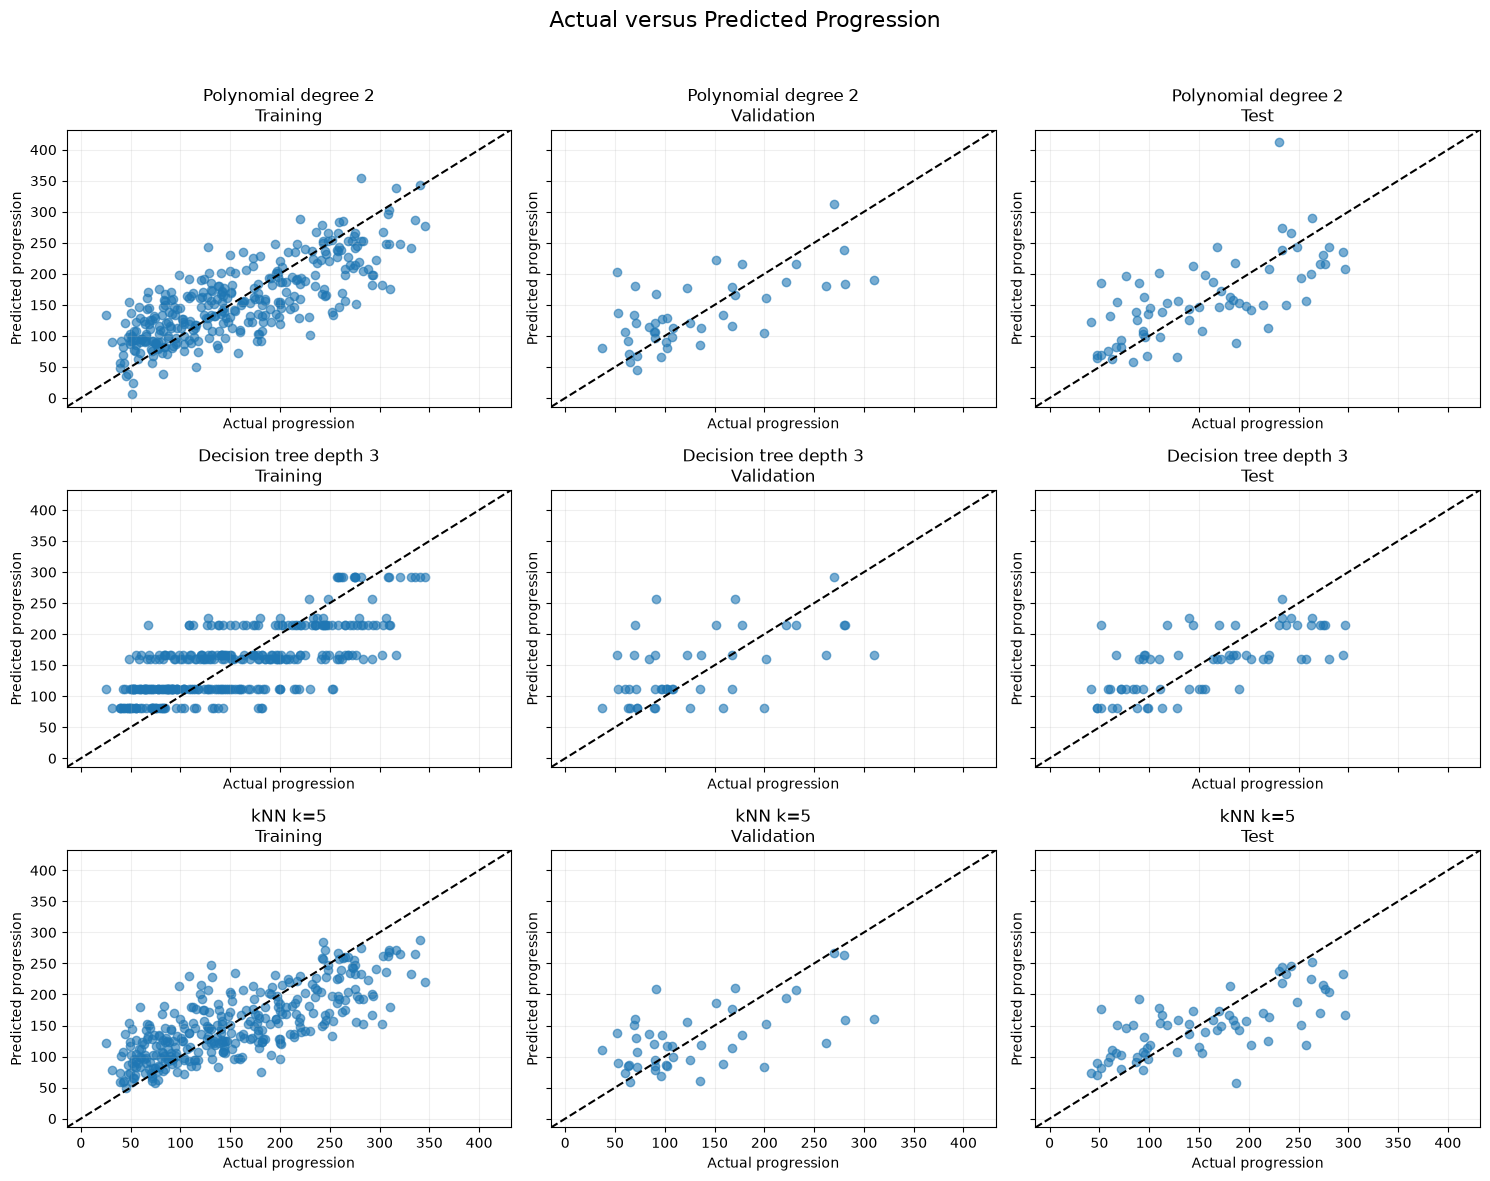

In [36]:
from src.regression_visualizer import RegressionComparisonVisualizer

dataset_splits = {
    "Training": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test)
}

regression_visualizer = RegressionComparisonVisualizer()

regression_visualizer.plot_predictions(
    experiment=multivariate_experiment,
    model_names=selected_model_names,
    splits=dataset_splits
)

## 46. Inspect Errors in the Selected Overall Model

The degree-2 polynomial was selected overall using validation MAE.

We examine its largest test errors and compare errors across the
same progression groups used in Part 2. This helps us assess whether
using multiple features reduced the BMI-only model's weaknesses.

The groups describe actual outcomes and are not clinical risk labels.

,bmi,actual,predicted,residual,absolute_error
321,31.2,230.0,411.99,-181.99,181.99
380,28.8,52.0,185.35,-133.35,133.35
209,24.7,77.0,196.79,-119.79,119.79
287,25.8,219.0,113.31,105.69,105.69
395,26.5,258.0,156.53,101.47,101.47
244,31.4,187.0,87.89,99.11,99.11
199,22.2,90.0,184.95,-94.95,94.95
388,24.1,110.0,201.28,-91.28,91.28
113,27.7,297.0,207.62,89.38,89.38
22,26.0,68.0,155.06,-87.06,87.06


,patients,MAE,mean_residual
progression_group,,,
Lower,14,45.30,-41.65
Middle,35,38.76,-6.00
Higher,18,58.74,27.73


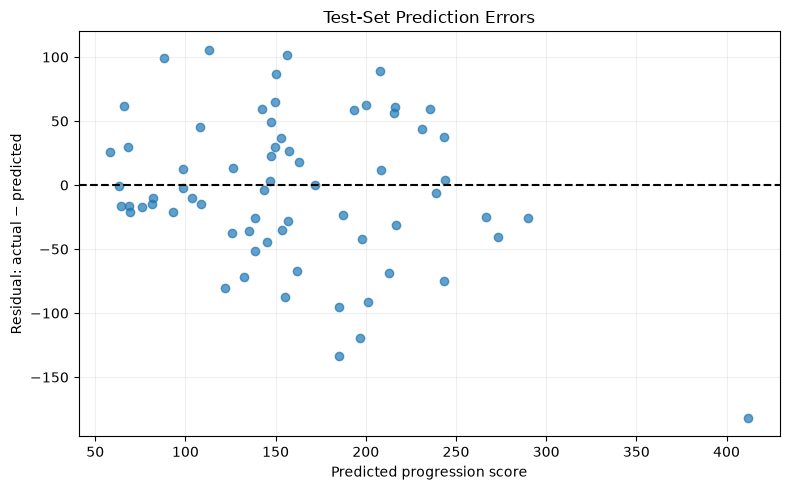

In [37]:
multivariate_error_analyzer = RegressionErrorAnalyzer(
    X=X_test,
    y_true=y_test,
    y_pred=multivariate_test_predictions[best_multivariate_name]
)

display(
    multivariate_error_analyzer.get_largest_errors().round(2)
)

display(
    multivariate_error_analyzer.get_group_summary(y_train).round(2)
)

multivariate_error_analyzer.plot_residuals()

## 47. Test Results and Error Analysis

All three selected multivariate models improved upon the BMI-only
model across the test metrics.

The degree-2 polynomial was selected using validation MAE. However,
kNN with five neighbors achieved the best test results:
R² = 0.471, MAE = 42.21, and MAPE = 34.65%.
This difference shows that model rankings can vary between samples.
We retain our validation-based selection.

The plots show substantial prediction errors for all three models.
The decision tree produces horizontal bands because patients in the
same leaf receive the same prediction.

For the degree-2 polynomial, MAE was 45.30 for lower progression,
38.76 for middle progression, and 58.74 for higher progression.
Compared with the BMI-only model, errors decreased in the lower
and higher groups but increased slightly in the middle group.

The model still overpredicted the lower group and underpredicted
the higher group on average. Its largest error was a prediction
of 411.99 for an actual score of 230. Polynomial predictions are
not constrained to the observed target range.

### Decision Tree and kNN Error Analysis

We examine the largest test errors for the selected decision tree
and kNN models.

We also compare errors across lower, middle, and higher progression
groups, using the same training-derived boundaries as before.

A positive mean residual indicates average underprediction.
A negative mean residual indicates average overprediction.
These groups describe actual outcomes, not clinical risk categories.

In [38]:
for model_name in ["Decision tree depth 3", "kNN k=5"]:
    print(f"\n{model_name}")

    analyzer = RegressionErrorAnalyzer(
        X=X_test,
        y_true=y_test,
        y_pred=multivariate_test_predictions[model_name]
    )

    print("Three largest prediction errors:")
    display(
        analyzer.get_largest_errors(number=3).round(2)
    )

    print("Errors by progression group:")
    display(
        analyzer.get_group_summary(y_train).round(2)
    )


Decision tree depth 3
Three largest prediction errors:


,bmi,actual,predicted,residual,absolute_error
380,28.8,52.0,215.04,-163.04,163.04
172,33.0,295.0,167.19,127.81,127.81
117,24.4,281.0,159.57,121.43,121.43


Errors by progression group:


,patients,MAE,mean_residual
progression_group,,,
Lower,14,49.98,-49.98
Middle,35,39.26,-6.20
Higher,18,56.45,53.86



kNN k=5
Three largest prediction errors:


,bmi,actual,predicted,residual,absolute_error
395,26.5,258.0,119.2,138.8,138.8
113,27.7,297.0,166.6,130.4,130.4
244,31.4,187.0,58.0,129.0,129.0


Errors by progression group:


,patients,MAE,mean_residual
progression_group,,,
Lower,14,47.21,-47.21
Middle,35,32.23,2.77
Higher,18,57.71,55.18


### Decision Tree and kNN Error Analysis

The depth-3 decision tree performed best for the middle progression
group (MAE 39.26) and worst for the higher group (MAE 56.45).
It overpredicted the lower group by 49.98 points on average and
underpredicted the higher group by 53.86 points. Its largest error
was predicting 215.04 for an actual score of 52.

The kNN model also performed best for the middle group (MAE 32.23)
and worst for the higher group (MAE 57.71). It overpredicted the
lower group by 47.21 points on average and underpredicted the
higher group by 55.18 points. Its largest error was predicting
119.20 for an actual score of 258.

Compared with the tree, kNN had lower MAE in the lower and middle
groups but slightly higher MAE in the higher group. Both models
struggled with extreme progression scores despite reasonable
overall performance.

## 48. Equation of the Selected Polynomial Model

The selected degree-2 model uses standardized versions of all
10 input features.

For each feature:

z_feature = (feature − training mean) / training scale

Its equation contains an intercept, linear terms, squared terms,
and pairwise interactions:

Predicted progression =
intercept + linear contributions + squared contributions
+ interaction contributions.

The coefficient table below specifies every term in this equation.
For example, z_bmi^2 is squared standardized BMI, while
z_bmi z_bp means standardized BMI multiplied by standardized
blood pressure.

Coefficients are displayed to two decimal places. Predictions
continue to use the fitted model at full precision.

In [39]:
from src.multivariate_inspector import MultivariateModelInspector

multivariate_inspector = MultivariateModelInspector(
    experiment=multivariate_experiment,
    feature_names=X_train.columns
)

coefficient_table, scaling_table = (
    multivariate_inspector.get_polynomial_details(
        model_name=best_multivariate_name
    )
)

print("Definitions of standardized inputs:")
display(scaling_table.round(6))

print("Complete equation coefficients:")
with pd.option_context("display.max_rows", None):
    display(coefficient_table.round(2))

Definitions of standardized inputs:


,Feature,Scaled variable,Training mean,Training scale
0,age,z_age,48.797583,12.770510
1,sex,z_sex,1.471299,0.499176
2,bmi,z_bmi,26.591541,4.373650
3,bp,z_bp,95.023112,13.891902
4,s1,z_s1,189.546828,34.929624
5,s2,z_s2,115.469789,30.804010
6,s3,z_s3,49.626888,12.768230
7,s4,z_s4,4.093625,1.307926
8,s5,z_s5,4.660475,0.526271
9,s6,z_s6,92.045317,11.445169


Complete equation coefficients:


,Term,Coefficient
0,Intercept,169.36
1,z_age,6.64
2,z_sex,-14.54
3,z_bmi,18.63
4,z_bp,20.83
5,z_s1,318.66
6,z_s2,-284.95
7,z_s3,-136.21
8,z_s4,-3.17
9,z_s5,-75.60


## 49. Model Complexity

With 10 inputs, degree 2 generates 65 polynomial terms:
10 linear terms, 10 squared terms, and 45 pairwise interactions.
Including the intercept gives 66 coefficient slots.

Degree 3 generates 285 terms, or 286 coefficient slots including
the intercept.

These counts do not necessarily represent independently identifiable
parameters. Some terms are redundant, particularly powers of the
binary-coded sex variable. The reported design rank helps identify
this dependence, so individual coefficients require caution.

Decision trees learn split features, thresholds, and leaf predictions.
Their complexity is described using depth, node count, and leaf count.

kNN does not fit a polynomial coefficient vector. It stores training
examples and predicts from nearby patients. The value of k is a
chosen hyperparameter, not a fitted coefficient.

Scaling statistics are preprocessing quantities and are reported
separately from regression coefficients.

In [40]:
complexity_table = multivariate_inspector.get_complexity()

with pd.option_context("display.max_colwidth", None):
    display(complexity_table)

,Model,Complexity
0,Polynomial degree 2,65 polynomial terms; 66 coefficient slots including intercept; centered design rank = 64
1,Polynomial degree 3,285 polynomial terms; 286 coefficient slots including intercept; centered design rank = 270
2,Decision tree depth 3,Actual depth = 3; nodes = 15; leaves = 8
3,Decision tree depth 5,Actual depth = 5; nodes = 61; leaves = 31
4,kNN k=5,k = 5; stores training examples; no fitted regression coefficients
5,kNN k=15,k = 15; stores training examples; no fitted regression coefficients


## 50. Predict for an Example Patient

A multivariate prediction requires all 10 baseline measurements.

We use the first training patient's recorded measurements as a
demonstration. This avoids inventing an inconsistent combination
of patient values.

We compare predictions from the three selected models. Because
this patient belongs to the training set, this example demonstrates
how predict() works; it is not evidence of performance on unseen data.

Changing only BMI while omitting the other measurements would not
provide a complete input for these models.

In [41]:
example_patient_all = X_train.iloc[[0]].copy()

print("Example patient's baseline measurements:")
display(example_patient_all)

example_prediction_rows = []

for model_name in selected_model_names:
    prediction = multivariate_experiment.predict(
        model_name=model_name,
        X=example_patient_all
    )[0]

    example_prediction_rows.append({
        "Model": model_name,
        "Predicted progression": prediction
    })

display(
    pd.DataFrame(example_prediction_rows).round(2)
)

Example patient's baseline measurements:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
16,47.0,1.0,30.3,109.0,207.0,100.2,70.0,3.0,5.2149,98.0


,Model,Predicted progression
0,Polynomial degree 2,206.07
1,Decision tree depth 3,215.04
2,kNN k=5,174.40


## 51. Part 3 Regression Conclusion

### Performance

Using multiple features improved test performance compared with
the BMI-only model.

The degree-2 polynomial was selected using validation MAE. Its test
results were R² = 0.399, MAE = 45.49, and MAPE = 37.95%.

kNN with five neighbors achieved the best results on this test sample:
R² = 0.471, MAE = 42.21, and MAPE = 34.65%. However, our overall
selection remains the degree-2 polynomial because model selection
was based on validation data.

### Errors and Limitations

The degree-3 polynomial severely overfit, while increasing tree
depth also worsened validation performance. Greater complexity
did not guarantee better predictions.

The selected degree-2 model still overpredicted lower progression
scores and underpredicted higher scores on average. Its largest
test error was approximately 182 points, showing that improved
average performance does not guarantee reliable individual predictions.

Polynomial models can produce extreme predictions, trees produce
constant predictions within leaves, and kNN depends on feature
scaling and the available neighboring patients.

### Workshop Connections

The Performance Metrics workshop highlighted why several metrics
and detailed error analysis are needed. The kNN workshop emphasized
scaling, neighbor selection, and limitations of small samples.
The Logistic Regression workshop showed that probabilities and
classification thresholds require a clearly defined categorical target.

The small dataset and single split limit confidence in model rankings.
Further evaluation could use cross-validation within the training
data and independent patient data. These results alone do not
establish suitability for clinical screening.

## 52. Logistic Regression: Define the Classification Task

Logistic Regression predicts categories rather than a numerical
progression score.

Because the assignment does not define categories, we use this
documented assumption:

- Class 0: Progression below the training-set median.
- Class 1: Progression at or above the training-set median.

The median is calculated using training outcomes only. The same
boundary is then applied to validation and test outcomes.

These categories are statistical labels, not validated clinical
risk levels. This assumption requires instructor confirmation.

The original numerical target remains unchanged for regression.

## 53. Train Two Logistic Regression Models

We use all 10 input features and compare C=0.1 with C=1.0.
The smaller C applies stronger regularization, which discourages
large coefficients.

Each model uses a pipeline that fits feature scaling on training
data only.

We compare accuracy, precision, recall, F1, and ROC AUC. These are
classification metrics, so they are kept separate from the
regression results.

Both models predict class 1 when its predicted probability is
at least 0.5.

In [42]:
from src.logistic_models import LogisticModelComparison

logistic_experiment = LogisticModelComparison(
    random_state=42
)

logistic_results = logistic_experiment.train_and_compare(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val
)

print(
    "Progression boundary defining class 1:",
    logistic_experiment.target_threshold
)

with pd.option_context("display.max_columns", None):
    display(logistic_results.round(3))

Progression boundary defining class 1: 142.0


,Model,C,Train Accuracy,Train Precision,Train Recall,Train F1,Train ROC AUC,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC AUC
0,Logistic Regression C=0.1,0.1,0.746,0.747,0.756,0.751,0.840,0.795,0.688,0.733,0.71,0.837
1,Logistic Regression C=1.0,1.0,0.752,0.753,0.762,0.757,0.841,0.795,0.688,0.733,0.71,0.832


## 54. Select the Classifier

We select the model with the highest validation F1, balancing
precision and recall. If F1 is tied, we prefer higher recall,
then the smaller C.

Recall measures how many actual class-1 patients are identified.
Precision measures how many predicted class-1 patients actually
belong to class 1.

We also report training and validation class counts to help
interpret the results. Test results are not used for selection.

In [43]:
class_counts = pd.DataFrame({
    "Training": logistic_experiment.create_labels(
        y_train
    ).value_counts(),

    "Validation": logistic_experiment.create_labels(
        y_val
    ).value_counts()
}).reindex([0, 1]).fillna(0).astype(int)

class_counts.index.name = "Class"

display(class_counts)

ranked_logistic_models = logistic_results.sort_values(
    by=["Validation F1", "Validation Recall", "C"],
    ascending=[False, False, True]
)

best_logistic_name = ranked_logistic_models.iloc[0]["Model"]

display(
    ranked_logistic_models[
        [
            "Model",
            "Validation Precision",
            "Validation Recall",
            "Validation F1",
            "Validation ROC AUC"
        ]
    ].round(3)
)

print("Selected classifier:", best_logistic_name)

,Training,Validation
Class,,
0,163,29
1,168,15


,Model,Validation Precision,Validation Recall,Validation F1,Validation ROC AUC
0,Logistic Regression C=0.1,0.688,0.733,0.71,0.837
1,Logistic Regression C=1.0,0.688,0.733,0.71,0.832


Selected classifier: Logistic Regression C=0.1


Both models achieved validation F1 = 0.710 and recall = 0.733.
Following our stated tie-break rule, we selected C=0.1, which
applies stronger regularization.

Its validation ROC AUC was 0.837, compared with 0.832 for C=1.0.
This small difference does not establish a reliable performance
advantage on only 44 validation patients.

## 55. Test Evaluation

We evaluate the validation-selected classifier, C=0.1, on the
67 test patients without retraining or changing its thresholds.

Class 1 means actual progression at or above 142.0.
The predicted category uses a probability threshold of 0.5.

The confusion matrix shows correct classifications, false positives,
and false negatives. False negatives represent missed class-1
patients, not missed diabetes diagnoses.

In [44]:
logistic_test_results, logistic_confusion_matrix = (
    logistic_experiment.evaluate_test(
        model_name=best_logistic_name,
        X_test=X_test,
        y_test=y_test
    )
)

display(logistic_test_results.round(3))
display(logistic_confusion_matrix)

false_negatives = logistic_confusion_matrix.loc[
    "Actual 1",
    "Predicted 0"
]

print("False negatives:", false_negatives)

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression C=0.1,0.716,0.735,0.714,0.725,0.854


,Predicted 0,Predicted 1
Actual 0,23,9
Actual 1,10,25


False negatives: 10


## 56. Classification Limitations

The classifier predicts a median-based category, not an exact
progression score or a diabetes diagnosis.

Patients just below and above the category boundary may have
similar outcomes despite receiving different labels. The boundary
does not establish clinical risk.

Changing the probability threshold would affect precision and recall.
We kept it fixed at 0.5 rather than tuning it on test data.

The small evaluation sets limit confidence in the results.
Classification metrics cannot be directly ranked against the
regression metrics because the prediction tasks differ.

### Classifier Equation and Parameters

The selected classifier estimates the probability of class 1:

p = 1 / (1 + exp(−η))

where η = intercept + Σ(coefficient × standardized feature).

Each standardized feature is calculated using its training mean
and scale. Class 1 is predicted when p is at least 0.5.

Each classifier fits 10 coefficients and one intercept, giving
11 regression parameters. Scaling statistics are stored separately.

In [45]:
selected_pipeline = logistic_experiment.models[best_logistic_name]

classifier = selected_pipeline.named_steps["classifier"]
classifier_scaler = selected_pipeline.named_steps["scaler"]

classifier_coefficients = pd.DataFrame({
    "Term": ["Intercept"] + [
        f"z_{feature}" for feature in X_train.columns
    ],
    "Coefficient": [
        classifier.intercept_[0]
    ] + classifier.coef_[0].tolist()
})

classifier_scaling = pd.DataFrame({
    "Feature": X_train.columns,
    "Training mean": classifier_scaler.mean_,
    "Training scale": classifier_scaler.scale_
})

display(classifier_coefficients.round(2))
display(classifier_scaling.round(6))

print("η =", f"{classifier.intercept_[0]:.2f}", end="")

for feature, coefficient in zip(
    X_train.columns,
    classifier.coef_[0]
):
    print(f" {coefficient:+.2f}*z_{feature}", end="")

print("\np = 1 / (1 + exp(-η))")
print("Fitted regression parameters:", classifier.coef_.size + 1)

,Term,Coefficient
0,Intercept,0.07
1,z_age,0.04
2,z_sex,-0.43
3,z_bmi,0.51
4,z_bp,0.48
5,z_s1,-0.15
6,z_s2,-0.19
7,z_s3,-0.38
8,z_s4,0.20
9,z_s5,0.55


,Feature,Training mean,Training scale
0,age,48.797583,12.770510
1,sex,1.471299,0.499176
2,bmi,26.591541,4.373650
3,bp,95.023112,13.891902
4,s1,189.546828,34.929624
5,s2,115.469789,30.804010
6,s3,49.626888,12.768230
7,s4,4.093625,1.307926
8,s5,4.660475,0.526271
9,s6,92.045317,11.445169


η = 0.07 +0.04*z_age -0.43*z_sex +0.51*z_bmi +0.48*z_bp -0.15*z_s1 -0.19*z_s2 -0.38*z_s3 +0.20*z_s4 +0.55*z_s5 +0.07*z_s6
p = 1 / (1 + exp(-η))
Fitted regression parameters: 11


### Example Classification Prediction

We use one training patient's measurements to demonstrate prediction.
This example does not measure performance on unseen patients.

The probability refers to progression at or above 142.0, not the
probability of having diabetes.

In [46]:
example_classification_patient = X_train.iloc[[0]].copy()

predicted_class, class_probability = logistic_experiment.predict(
    model_name=best_logistic_name,
    X=example_classification_patient
)

display(example_classification_patient)

print("Predicted class:", predicted_class[0])
print(f"Class-1 probability: {class_probability[0]:.3f}")

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
16,47.0,1.0,30.3,109.0,207.0,100.2,70.0,3.0,5.2149,98.0


Predicted class: 1
Class-1 probability: 0.779


### Confusion Matrix Visualization

The heatmap displays the selected classifier's test predictions.
Rows show actual categories and columns show predicted categories.
Off-diagonal values represent classification errors.

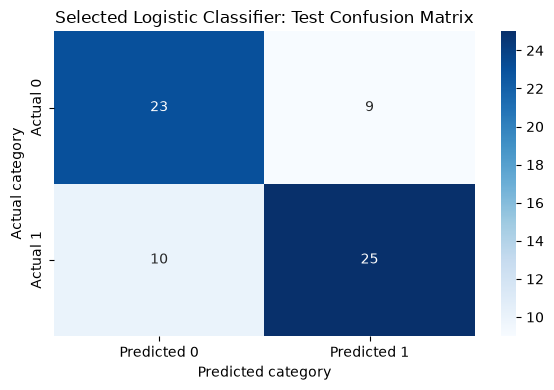

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    logistic_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Selected Logistic Classifier: Test Confusion Matrix")
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.tight_layout()
plt.show()

The example patient received a class-1 probability of 0.779.
Because this exceeds 0.5, the predicted category is progression
at or above 142.0.

This is a model-estimated probability for our statistical category,
not the probability of having diabetes. The patient belongs to the
training set, so this example demonstrates prediction rather than
performance on unseen patients.

## 57. Logistic Regression Conclusion

Both models achieved the same validation F1 and recall. Following
our tie-break rule, we selected C=0.1, which applies stronger
regularization.

On the test set, the selected classifier achieved accuracy of 71.6%,
precision of 73.5%, recall of 71.4%, F1 of 0.725, and ROC AUC of 0.854.

It correctly identified 25 of the 35 class-1 patients but missed 10.
It also incorrectly classified 9 class-0 patients as class 1.
Therefore, useful discrimination does not mean all patients are
classified reliably.

These results apply to the statistical boundary of progression
at or above 142.0, not a validated clinical risk category.
The classifier is not a diabetes diagnostic tool.

## References

1. [Scikit-Learn: Diabetes dataset description](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset)

2. [Scikit-Learn: load_diabetes documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)

3. [Scikit-Learn: LogisticRegression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

4. [Logistic Regression Classifier Workshop](https://github.com/ProfEspinosaAIML/LogisticRegressionClassifier_Workshop)

5. [K-Nearest Neighbors Workshop](https://github.com/AlamirConestoga/KNearestNeighbors_Workshop-main)

6. [Performance Metrics for Classification Workshop](https://github.com/AryaPatel-27/PerformanceMetricsClassification)